# 1016 — spot test 結果判讀

10/12 點盤、10/16 看結果。7 株菌的 double-layer lawn（200 µL 菌液 + 3 mL soft agar），每盤分 5 區，每區點 7 µL：

| 區 | 內容 | 角色 |
|---|---|---|
| `Φ8` | phage 原液 | positive control |
| `PBS` | 1× PBS | negative control |
| `e1` | 純化 e1，1:10 | |
| `e40` | e40 crude lysate，1:10 | |
| `e281` | e281 crude lysate，1:10 | |

- 照片：[`../data/assays/1016_spot_test/`](../data/assays/1016_spot_test/)，`_F` = 正面（寫菌株名），`_B` = 背面（畫線、寫區名）
- 背面的字從背面拍是鏡像：`SBd` = PBS、`1e` = e1、`04e` = e40、`182e` = e281
- 這裡把背面照片**左右翻轉**，等於從正面看，再依「標籤落在哪一區」指派每一滴

**10/18 跟 Alex 確認過**
- lawn 長得不錯。
- 1:10 都是用 PBS 稀釋，PBS 有滅菌。
- Φ8 那區以大圈為主（這裡量的就是大圈）。
- 9-1-1 的區指派正確。

**還沒確認**
- `1015_spot_test_dilution.ipynb` 寫的是「明天（10/16）spot test」用的等濃度稀釋表，但這批盤 10/12 就點了、用的是 1:10，所以**沒用那張表**，各管蛋白量不同、沒量過。
- `e1` 寫「純化」，但 notebook 裡沒有 e1 純化成功的紀錄（10/01 純化 CDS10 / e40，10/10 e281 失敗）；1015 有 `e1+`、`e40-`，這次點哪一管？
- R1 = 10/10 送 WGS（SBYK6W）的那兩株嗎？

In [1]:
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from scipy import ndimage
import matplotlib.pyplot as plt

IMG = '../data/assays/1016_spot_test'
OUT = 'output/1016_spot_test_result'
CROP = (230, 360, 750, 880)    # 翻轉後的背面照片裡，平板的範圍 (px)
Z = 900 / 520                  # 下面座標是在放大到 900 px 的圖上量的
COLS = ['phi8', 'PBS', 'e1', 'e40', 'e281']

## 1. 每一滴的位置

座標 = 翻轉 + 裁切 + 放大到 900 px 後的圖上，每滴的圓心。每個標籤都確認過落在單一區內、五個標籤各佔一區。
`Φ8` 區通常有兩個圈（一大一小），Φ8 以大圈為主，取的是大圈；`9-1-1` 的 `e281` 只看到一個很小的淡圈。

In [2]:
spots = {
    '9-2-1':    {'phi8': (445, 700), 'PBS': (645, 505), 'e1': (230, 500), 'e40': (340, 280), 'e281': (560, 315)},
    '9-2-1_R1': {'phi8': (540, 690), 'PBS': (655, 480), 'e1': (275, 615), 'e40': (255, 340), 'e281': (535, 315)},
    '9-6-2':    {'phi8': (385, 680), 'PBS': (245, 560), 'e1': (310, 320), 'e40': (555, 340), 'e281': (605, 580)},
    '9-6-2_R1': {'phi8': (370, 670), 'PBS': (650, 510), 'e1': (210, 450), 'e40': (390, 210), 'e281': (605, 295)},
    '8-10-2':   {'phi8': (365, 730), 'PBS': (225, 545), 'e1': (335, 320), 'e40': (590, 350), 'e281': (605, 640)},
    '9-1-1':    {'phi8': (350, 710), 'PBS': (565, 665), 'e1': (265, 455), 'e40': (440, 245), 'e281': (725, 505)},
    '10-10-2':  {'phi8': (285, 680), 'PBS': (240, 460), 'e1': (430, 285), 'e40': (630, 430), 'e281': (570, 660)},
}

def plate(name, mode='RGB'):
    return ImageOps.mirror(Image.open(f'{IMG}/{name}_B.jpeg').convert(mode)).crop(CROP)

## 2. 矩陣圖

列 = 菌株（親代 / R1 成對放），欄 = 5 種處理；最左是整盤（看得到手寫標籤，可以自己核對指派）。原始顏色，沒調色。

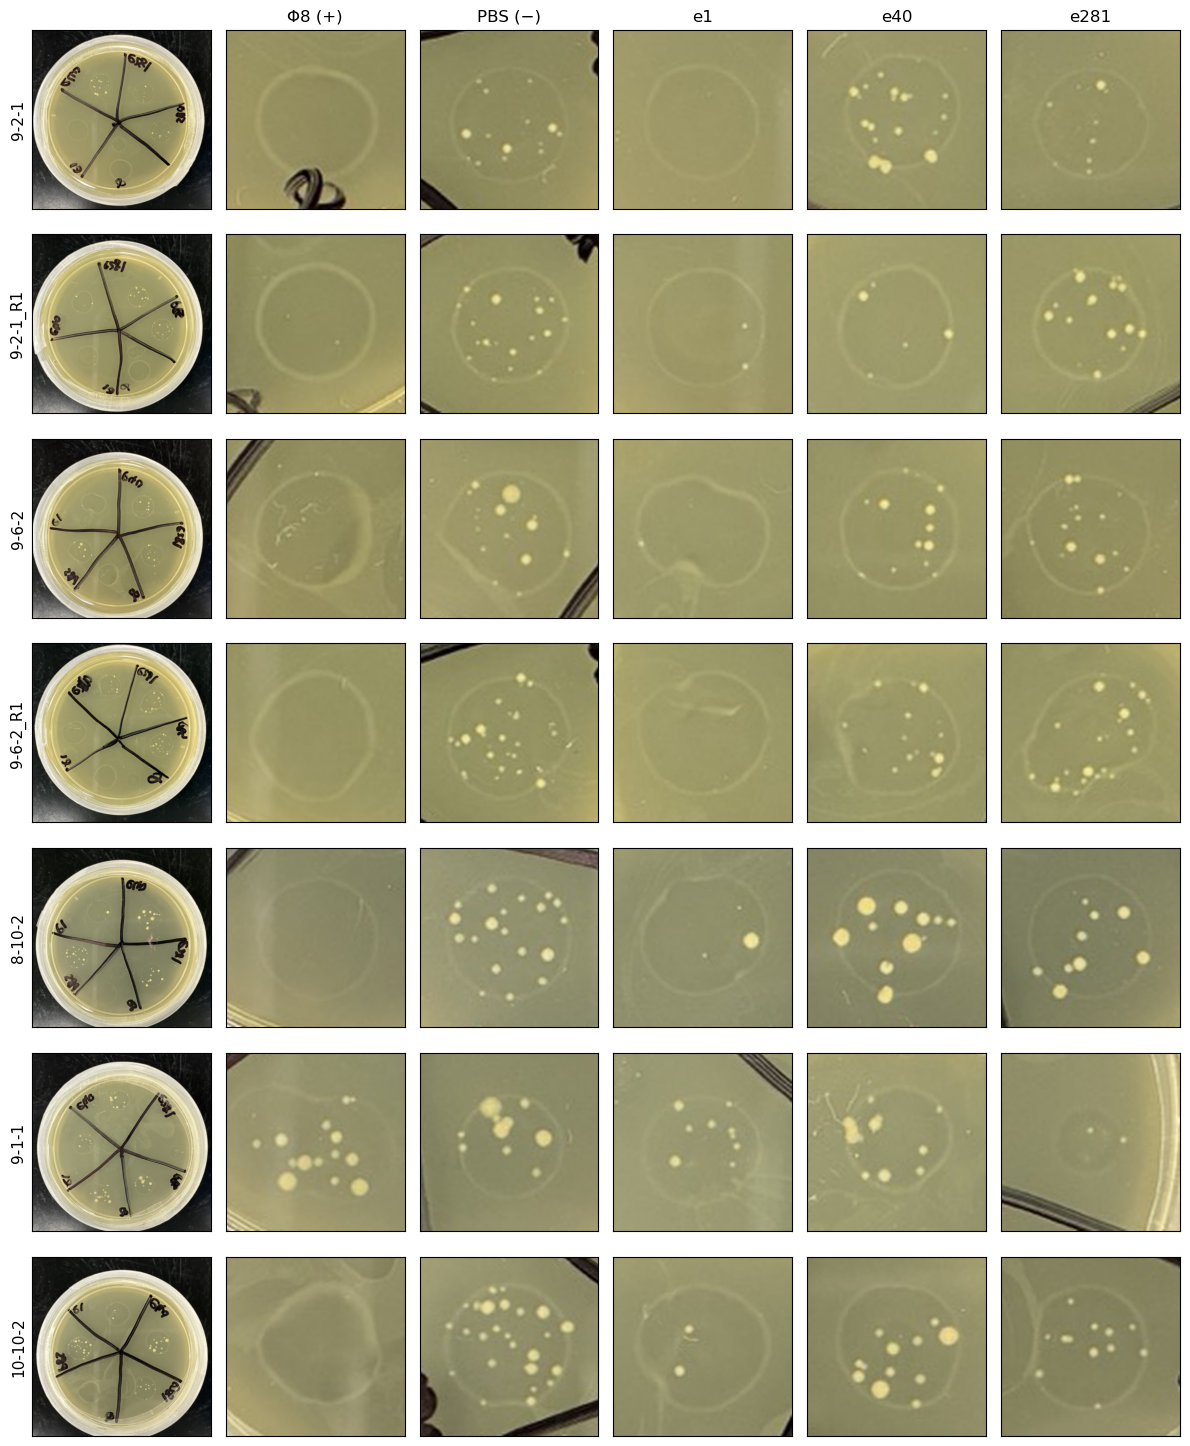

In [3]:
fig, ax = plt.subplots(len(spots), 6, figsize=(12, 2.1 * len(spots)))
for i, (p, d) in enumerate(spots.items()):
    im = plate(p)
    ax[i, 0].imshow(im)
    ax[i, 0].set_ylabel(p, fontsize=11)
    for j, k in enumerate(COLS):
        x, y = d[k][0] / Z, d[k][1] / Z
        ax[i, j + 1].imshow(im.crop((x - 48, y - 48, x + 48, y + 48)).resize((300, 300), Image.LANCZOS))
        if i == 0:
            ax[i, j + 1].set_title({'phi8': 'Φ8 (+)', 'PBS': 'PBS (−)'}.get(k, k))
    for a in ax[i]:
        a.set_xticks([]); a.set_yticks([])
fig.tight_layout()
fig.savefig(f'{OUT}/spot_matrix.png', dpi=200)
plt.show()

## 3. 每滴裡的菌落數

半徑 30 px 的圓內，比圓內中位數亮 22 以上、≥ 3 px 的連通塊算一顆。黏在一起的會算成一顆，所以是**下限**；`9-6-2` Φ8 的 3 顆是圈邊的反光，不是菌落。

In [4]:
rows = []
for p, d in spots.items():
    g = np.asarray(plate(p, 'L'), float)
    yy, xx = np.mgrid[:g.shape[0], :g.shape[1]]
    for k in COLS:
        x, y = d[k][0] / Z, d[k][1] / Z
        r = np.hypot(xx - x, yy - y)
        disk = r < 30
        lab, n = ndimage.label((g > np.median(g[disk]) + 22) & disk)
        sizes = ndimage.sum(np.ones_like(g), lab, range(1, n + 1))
        clear = np.median(g[r < 20]) - np.median(g[(r > 35) & (r < 46)])   # 負 = 比外面暗 = 比較透
        rows.append(dict(strain=p, spot=k, colonies=int((sizes >= 3).sum()), inside_minus_lawn=clear))
res = pd.DataFrame(rows)
counts = res.pivot(index='strain', columns='spot', values='colonies').loc[list(spots), COLS]
counts

spot,phi8,PBS,e1,e40,e281
strain,,,,,
9-2-1,0,11,0,13,5
9-2-1_R1,0,14,1,4,11
9-6-2,3,8,1,8,9
9-6-2_R1,0,17,1,11,13
8-10-2,0,15,3,10,7
9-1-1,11,7,8,9,2
10-10-2,1,17,4,10,9


## 4. 有沒有透（lysis）

圓內亮度 − 圓外 lawn 亮度。背景是黑桌面，越透越暗 → 負值。差異只有幾個灰階，**很弱**，只當輔助；肉眼在矩陣圖上看不到任何一滴有明顯透明區。

In [5]:
bright = res.pivot(index='strain', columns='spot', values='inside_minus_lawn').loc[list(spots), COLS].round(1)
res.to_csv(f'{OUT}/spot_calls.tsv', sep='\t', index=False)
print('每盤最暗（最透）的那滴:', bright.idxmin(axis=1).to_dict())
bright

每盤最暗（最透）的那滴: {'9-2-1': 'phi8', '9-2-1_R1': 'phi8', '9-6-2': 'phi8', '9-6-2_R1': 'phi8', '8-10-2': 'phi8', '9-1-1': 'e40', '10-10-2': 'phi8'}


spot,phi8,PBS,e1,e40,e281
strain,,,,,
9-2-1,-4.0,0.0,-2.0,1.0,-1.0
9-2-1_R1,-3.0,1.0,-1.0,0.0,-2.0
9-6-2,-4.0,-2.0,-2.0,-1.0,-1.0
9-6-2_R1,-4.0,0.0,0.0,-2.0,-1.0
8-10-2,-3.0,0.0,-1.0,3.0,-2.0
9-1-1,-3.0,-2.0,-3.0,-4.0,-1.0
10-10-2,-9.0,2.0,-1.0,-3.0,-1.0


## 5. 判讀

**看得到的**
1. **照片上看不到明顯的透明區**，包括 Φ8 點在它自己的宿主 9-2-1、9-6-2 上（lawn 本身長得不錯）。亮度上 Φ8 是 6/7 盤最暗的一滴，但只差幾個灰階。
2. **PBS、e40、e281 滴裡每一盤都長菌落**（中位數 14 / 10 / 9），菌落長相一樣（奶黃色、圓、大小不一）。
3. **Φ8 滴幾乎沒有菌落**（中位數 0），**純化 e1 滴也幾乎沒有**（中位數 1）。9-1-1 例外，Φ8 和 e1 滴也長菌落。
4. R1 和親代看起來一樣。

**怎麼解讀**
- PBS 有滅菌，所以滴裡的菌落**不是液體帶進來的雜菌**，也不是裂解後的存活菌（PBS 不會裂解）；比較像 lawn 本身的菌在被液體弄濕的那一圈長成獨立菌落。來源還不確定，但它是「一滴 PBS 落在這種 lawn 上」的基準。
- 所有樣品都用 PBS 1:10 稀釋，e1 滴有 90% 是 PBS，卻幾乎沒有菌落 → **差別來自 e1 那 10%**，跟 Φ8 的效果接近。
- e40、e281 是 crude lysate，菌落只比 PBS 少一點；這不代表它們沒活性，它們沒純化，有效成分濃度可能低很多。
- 剩下的干擾：e1 的 elution buffer（例如 imidazole）也在那 10% 裡，要點一滴「elution buffer 1:10」才能排除。
- 因為親代上也沒看到透明區，**R1 有沒有抗性還不能判斷**。

**UNDONE**
- elution buffer 1:10 單獨點一滴（排除 imidazole）
- e1 做稀釋系列（1:10、1:100、1:1000），看抑制會不會隨濃度消失
- e40、e281 純化後用等濃度再點（1015 的表）
- Φ8 做 10 倍稀釋系列，確認在親代上有 plaque，再拿來比 R1

## 6. 論文 / wiki 用的圖

A = 每滴的裁切（原始顏色），B = 每滴裡的菌落數，一點 = 一株菌，橫線 = 中位數。
caption 在 `output/1016_spot_test_result/figure_caption.md`。

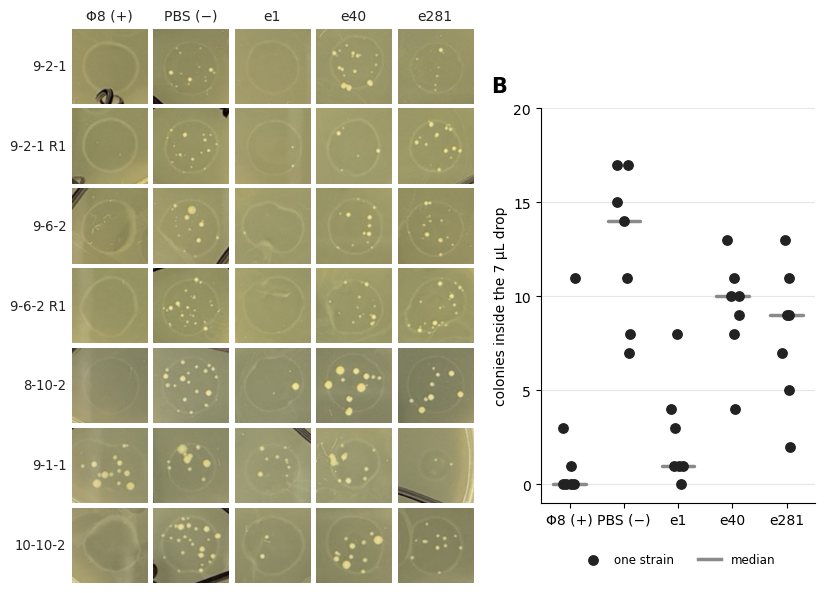

median colonies: {'phi8': 0.0, 'PBS': 14.0, 'e1': 1.0, 'e40': 10.0, 'e281': 9.0}


In [6]:
from matplotlib.gridspec import GridSpec

NAMES = {'phi8': 'Φ8 (+)', 'PBS': 'PBS (−)', 'e1': 'e1', 'e40': 'e40', 'e281': 'e281'}
ROWS = {'9-2-1': '9-2-1', '9-2-1_R1': '9-2-1 R1', '9-6-2': '9-6-2', '9-6-2_R1': '9-6-2 R1',
        '8-10-2': '8-10-2', '9-1-1': '9-1-1', '10-10-2': '10-10-2'}
INK, MUTED = '#222222', '#8a8a8a'

fig = plt.figure(figsize=(9.6, 7.2))
gs = GridSpec(len(spots), 7, figure=fig, width_ratios=[1] * 5 + [0.75, 3.6], wspace=0.05, hspace=0.06)
for i, (p, d) in enumerate(spots.items()):
    im = plate(p)
    for j, k in enumerate(COLS):
        a = fig.add_subplot(gs[i, j])
        x, y = d[k][0] / Z, d[k][1] / Z
        a.imshow(im.crop((x - 44, y - 44, x + 44, y + 44)).resize((240, 240), Image.LANCZOS))
        a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values():
            s.set_visible(False)
        if i == 0:
            a.set_title(NAMES[k], fontsize=10, color=INK)
        if j == 0:
            a.set_ylabel(ROWS[p], fontsize=9.5, color=INK, rotation=0, ha='right', va='center')

b = fig.add_subplot(gs[1:6, 6])
rng = np.random.default_rng(0)
for j, k in enumerate(COLS):
    sub = res[res.spot == k]
    jit = rng.uniform(-0.13, 0.13, len(sub))
    b.scatter(j + jit, sub.colonies, s=46, zorder=3, color=INK)
    m = sub.colonies.median()
    b.plot([j - 0.3, j + 0.3], [m, m], color=MUTED, lw=2.5, solid_capstyle='round', zorder=2)
b.set_xticks(range(len(COLS)), [NAMES[k] for k in COLS], fontsize=10)
b.set_ylabel('colonies inside the 7 µL drop', fontsize=10)
b.set_ylim(-1, 20)
b.set_yticks(range(0, 21, 5))
b.grid(axis='y', color='#e6e6e6', lw=0.8); b.set_axisbelow(True)
for s in ['top', 'right']:
    b.spines[s].set_visible(False)
b.text(-0.18, 1.04, 'B', transform=b.transAxes, fontsize=15, weight='bold')
b.scatter([], [], s=46, facecolor=INK, edgecolor=INK, label='one strain')
b.plot([], [], color=MUTED, lw=2.5, label='median')
b.legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2)
fig.savefig(f'{OUT}/fig_spot_test.png', dpi=300, bbox_inches='tight')
fig.savefig(f'{OUT}/fig_spot_test.pdf', bbox_inches='tight')
plt.show()
med = res.groupby('spot').colonies.median().loc[COLS]
print('median colonies:', med.to_dict())

## 7. 第二張圖 — 依 Φ8 宿主範圍分組

依 [`2026-07-04_host-range-results-matrix.md`](../lab_notebook/digitalized/2026-07-04_host-range-results-matrix.md)（18 hosts × 2 Φ8 lysates）：

- **Φ8 宿主**：9-2-1、9-6-2（Φ8 就是從這兩株分離的），加上它們的抗性衍生株 R1 → 4 列
- **非宿主**：8-10-2、9-1-1、10-10-2，三株對兩個 Φ8 lysate 都是 `F` → 3 列

一格 = 一滴，數字 = 滴內菌落數，顏色深淺跟著數字走（單一色相，淺 = 少）。

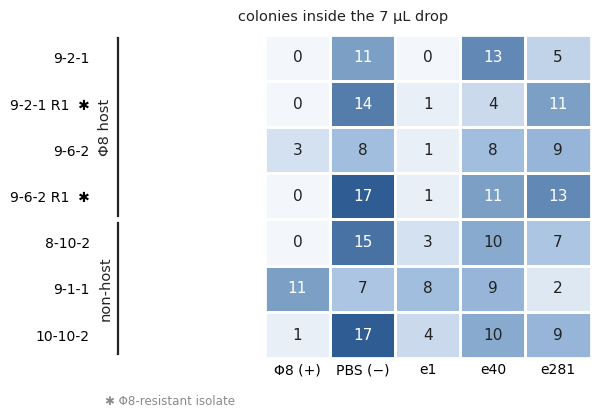

Φ8 host {'phi8': 0.0, 'PBS': 12.5, 'e1': 1.0, 'e40': 9.5, 'e281': 10.0}
non-host {'phi8': 1.0, 'PBS': 15.0, 'e1': 4.0, 'e40': 10.0, 'e281': 7.0}


In [7]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

GROUPS = [('Φ8 host', ['9-2-1', '9-2-1_R1', '9-6-2', '9-6-2_R1']),
          ('non-host', ['8-10-2', '9-1-1', '10-10-2'])]
RESISTANT = {'9-2-1_R1', '9-6-2_R1'}
LABEL = {'9-2-1': '9-2-1', '9-2-1_R1': '9-2-1 R1', '9-6-2': '9-6-2', '9-6-2_R1': '9-6-2 R1',
         '8-10-2': '8-10-2', '9-1-1': '9-1-1', '10-10-2': '10-10-2'}
ramp = LinearSegmentedColormap.from_list('seq', ['#f3f6fb', '#9dbbdd', '#2f5c92'])

order = [s for _, g in GROUPS for s in g]
M = res.pivot(index='strain', columns='spot', values='colonies').loc[order, COLS]

fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.imshow(M.values, cmap=ramp, vmin=0, vmax=M.values.max(), aspect='auto')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        ax.text(j, i, str(v), ha='center', va='center', fontsize=11,
                color='white' if v > M.values.max() * 0.6 else INK)
        ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor='white', lw=2))
ax.set_xticks(range(len(COLS)), [NAMES[k] for k in COLS], fontsize=10)
ax.set_yticks(range(len(order)),
              [LABEL[s] + ('  ✱' if s in RESISTANT else '') for s in order], fontsize=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)

# group brackets down the left
row = 0
for name, members in GROUPS:
    lo, hi = row - 0.42, row + len(members) - 0.58
    ax.plot([-2.75] * 2, [lo, hi], color=INK, lw=1.6, clip_on=False)
    ax.text(-2.95, (lo + hi) / 2, name, rotation=90, ha='center', va='center',
            fontsize=10.5, color=INK)
    row += len(members)
ax.text(-2.95, len(order) + 0.3, '✱ Φ8-resistant isolate', fontsize=8.5, color=MUTED,
        ha='left', va='top')
ax.set_title('colonies inside the 7 µL drop', fontsize=10.5, color=INK, pad=10)
fig.savefig(f'{OUT}/fig_spot_test_hostrange.png', dpi=300, bbox_inches='tight')
fig.savefig(f'{OUT}/fig_spot_test_hostrange.pdf', bbox_inches='tight')
plt.show()

for name, members in GROUPS:
    print(name, M.loc[members].median().to_dict())

## 8. 第三張圖 — 每盤用自己的 PBS 對照正規化

前兩張圖比的是絕對菌落數，但各盤的 PBS 基準本來就不同（7–17）。每一盤都自己帶了一滴 PBS，
所以把每滴換算成**「佔同一盤 PBS 對照的百分比」**，各株才真的可比。100% = 跟 PBS 一樣、沒有效果。

這樣會看到一個絕對數字看不出來的模式：7 株裡只有 **9-1-1** 一株，Φ8 和 e1 同時失效；
其他 6 株兩者都壓到 24% 以下。**e1 的活性是逐株跟著 Φ8 走的。**

註：host / non-host 分組切不開這批資料 — Φ8 在 8-10-2、10-10-2 這兩株非宿主上照樣壓住菌落
（0% 和 6%），所以「非宿主也有效 ⇒ 排除 phage carryover」這個推論**不成立**，不要這樣寫。

**UNDONE —依對「蛋白活性 vs phage carryover」的幫助排序**

1. **直接對 `e1` 製備液做 plaque assay**（9-2-1 菌苔、稀釋系列）。有 plaque = 活性不能歸給蛋白。
   一盤一天，而且上面所有解讀都卡在它 — 先做這個。
2. 單獨點一滴 elution buffer（1:10 於同一管 PBS），排除 imidazole 毒性。
3. `e1` 稀釋系列 1:10 / 1:100 / 1:1000，看抑制是不是隨稀釋呈梯度消退。
4. 把 CDS12_WT 放進同一盤 — 沒有它就沒有「祖先 vs 現代」的比較。
5. 確認 `e1` 那管的來源（notebook 裡沒有 e1 純化成功的紀錄），並用 anti-His western 或
   intact-mass MS 確認蛋白。
6. Φ8 在親代上做稀釋系列，建立 titre 與可見 plaque；R1 抗性要等這步才測得了。

完整說明與英文版：[`output/1016_spot_test_result/figure_caption.md`](output/1016_spot_test_result/figure_caption.md)。

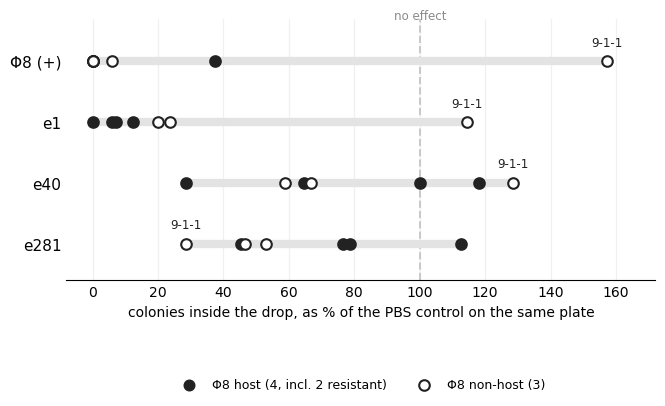

spot,e1,e281,e40,phi8
min,0.0,29.0,29.0,0.0
50%,12.0,53.0,67.0,0.0
max,114.0,112.0,129.0,157.0


In [8]:
pbs = res.pivot(index='strain', columns='spot', values='colonies')
pct = (pbs.div(pbs['PBS'], axis=0) * 100).drop(columns='PBS').loc[order]
TREAT = ['phi8', 'e1', 'e40', 'e281']
HOSTS = set(GROUPS[0][1])

fig, ax = plt.subplots(figsize=(7.6, 3.4))
ax.axvline(100, color='#c8c8c8', lw=1.4, ls='--', zorder=1)
ax.text(100, len(TREAT) - 0.36, 'no effect', fontsize=8.5, color=MUTED, ha='center', va='bottom')
for i, t in enumerate(TREAT):
    y = len(TREAT) - 1 - i
    ax.plot([pct[t].min(), pct[t].max()], [y, y], color='#e3e3e3', lw=6,
            solid_capstyle='round', zorder=1)
    for strain, v in pct[t].items():
        host = strain in HOSTS
        ax.scatter(v, y, s=58, zorder=3, linewidths=1.5,
                   facecolor=INK if host else 'white', edgecolor=INK)
        if strain == '9-1-1':
            ax.annotate('9-1-1', (v, y), textcoords='offset points', xytext=(0, 11),
                        ha='center', fontsize=8.5, color=INK)
ax.set_yticks(range(len(TREAT))[::-1], [NAMES[t] for t in TREAT], fontsize=11)
ax.set_xlabel('colonies inside the drop, as % of the PBS control on the same plate', fontsize=10)
ax.set_xlim(-8, 172)
ax.set_ylim(-0.6, len(TREAT) - 0.3)
ax.tick_params(length=0)
ax.grid(axis='x', color='#f0f0f0', lw=0.9)
ax.set_axisbelow(True)
for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)
ax.scatter([], [], s=58, facecolor=INK, edgecolor=INK, label='Φ8 host (4, incl. 2 resistant)')
ax.scatter([], [], s=58, facecolor='white', edgecolor=INK, lw=1.5, label='Φ8 non-host (3)')
ax.legend(frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.33), ncol=2)
fig.savefig(f'{OUT}/fig_spot_test_normalised.png', dpi=300, bbox_inches='tight')
fig.savefig(f'{OUT}/fig_spot_test_normalised.pdf', bbox_inches='tight')
plt.show()

summary = pct.describe().loc[['min', '50%', 'max']].round(0)
pct.round(0).to_csv(f'{OUT}/spot_percent_of_pbs.tsv', sep='\t')
summary